In [ ]:
!pip install kagglehub

In [ ]:
!pip install kagglehub

100%|██████████| 10.0M/10.0M [00:00<00:00, 67.6MB/s]

Extracting files...



Training Stacked_LSTM...
Epoch 1/2


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


548/548 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.7511 - loss: 0.5843 - val_accuracy: 0.9450 - val_loss: 0.1949
Epoch 2/2
548/548 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.9592 - loss: 0.1436 - val_accuracy: 0.9616 - val_loss: 0.1350
1251/1251 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step

Training Attention_LSTM...
Epoch 1/2
548/548 ━━━━━━━━━━━━━━━━━━━━ 20s 32ms/step - accuracy: 0.6821 - loss: 0.6900 - val_accuracy: 0.9586 - val_loss: 0.1385
Epoch 2/2
548/548 ━━━━━━━━━━━━━━━━━━━━ 16s 30ms/step - accuracy: 0.9663 - loss: 0.1145 - val_accuracy: 0.9682 - val_loss: 0.1088
1251/1251 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step

Training Stacked_CNN_BiLSTM...
Epoch 1/2


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


548/548 ━━━━━━━━━━━━━━━━━━━━ 16s 19ms/step - accuracy: 0.7397 - loss: 0.5943 - val_accuracy: 0.9575 - val_loss: 0.1447
Epoch 2/2
548/548 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.9680 - loss: 0.1134 - val_accuracy: 0.9651 - val_loss: 0.1216
1251/1251 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step

Training Hybrid_CNN_BiLSTM...
Epoch 1/2
548/548 ━━━━━━━━━━━━━━━━━━━━ 15s 23ms/step - accuracy: 0.7693 - loss: 0.5461 - val_accuracy: 0.9556 - val_loss: 0.1431
Epoch 2/2
548/548 ━━━━━━━━━━━━━━━━━━━━ 12s 23ms/step - accuracy: 0.9686 - loss: 0.1072 - val_accuracy: 0.9634 - val_loss: 0.1205
1251/1251 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step

--- PERFORMANCE SUMMARY ---
                Model  Accuracy  Precision    Recall        F1
0        Stacked_LSTM  0.959849   0.959833  0.959849  0.959786
1      Attention_LSTM  0.969893   0.969928  0.969893  0.969878
2  Stacked_CNN_BiLSTM  0.964371   0.964867  0.964371  0.964532
3   Hybrid_CNN_BiLSTM  0.963272   0.963746  0.963272  0.963430


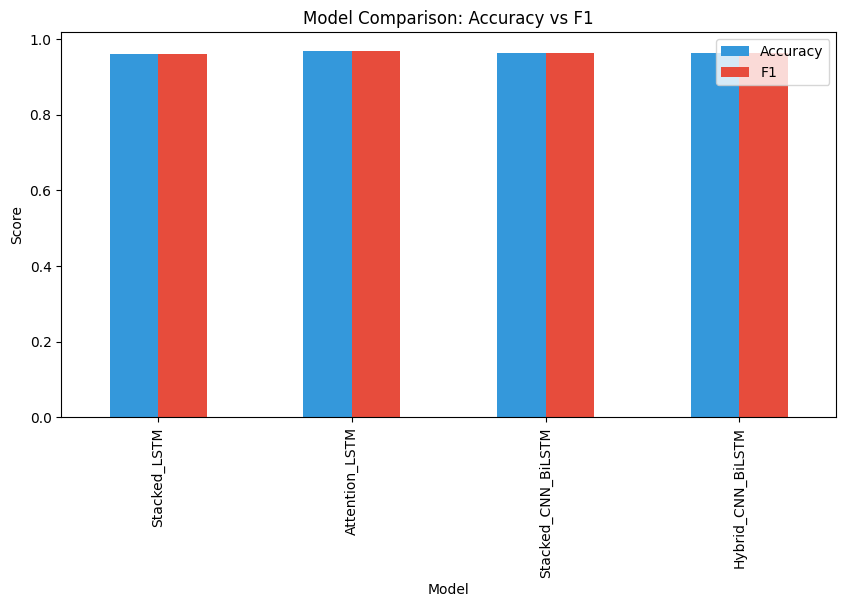

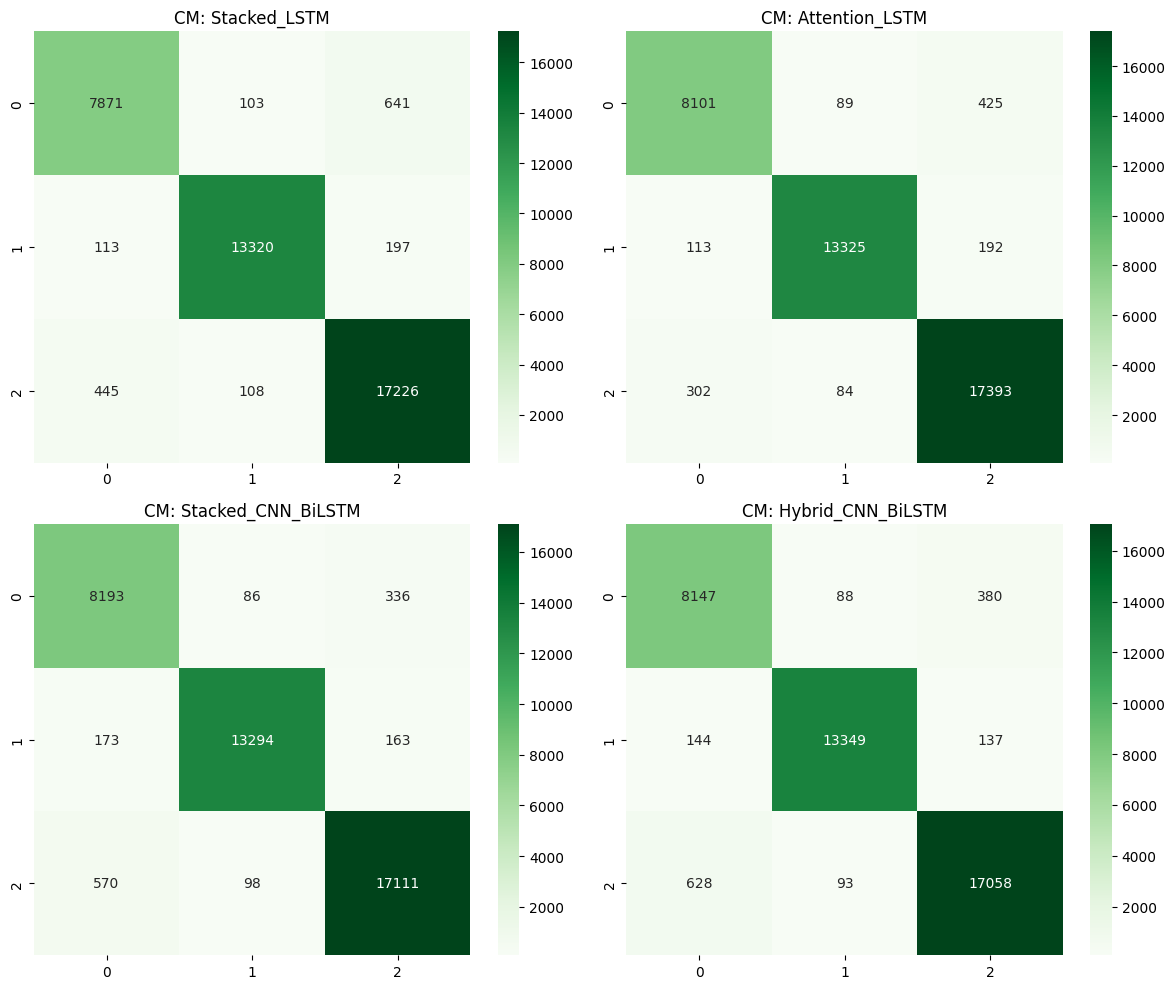

In [ ]:
import kagglehub
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import (Input, Embedding, LSTM, Dense, Dropout,
                                     Bidirectional, Conv1D, GlobalMaxPooling1D,
                                     Concatenate, Layer, MultiHeadAttention)
from tensorflow.keras.models import Model, Sequential

# --- 1. DOWNLOAD & CLEAN DATA ---
path = kagglehub.dataset_download("cosmos98/twitter-and-reddit-sentimental-analysis-dataset")

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)
    text = re.sub(r'[^a-z\s]', '', text)
    return " ".join(text.split())

# Load datasets (using the path provided by kagglehub)
df_tw = pd.read_csv(f"{path}/Twitter_Data.csv").rename(columns={'clean_text': 'text'})
df_rd = pd.read_csv(f"{path}/Reddit_Data.csv").rename(columns={'clean_comment': 'text'})

df = pd.concat([df_tw, df_rd], ignore_index=True).dropna()
df['text'] = df['text'].apply(clean_text)
df['category'] = df['category'].astype(int) + 1 # Map -1,0,1 to 0,1,2

# --- 2. 70/10/20 SPLIT & TOKENIZATION ---
MAX_WORDS, MAX_LEN = 10000, 100
tokenizer = Tokenizer(num_words=MAX_WORDS)
tokenizer.fit_on_texts(df['text'])

X = pad_sequences(tokenizer.texts_to_sequences(df['text']), maxlen=MAX_LEN)
y = tf.keras.utils.to_categorical(df['category'], 3)

# 70% Train, 10% Val, 20% Test
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.125, random_state=42)

# --- 3. MODEL BUILDERS ---

def build_stacked_lstm():
    return Sequential([
        Embedding(MAX_WORDS, 128, input_length=MAX_LEN),
        LSTM(64, return_sequences=True),
        LSTM(64),
        Dense(3, activation='softmax')
    ], name="Stacked_LSTM")

def build_attention_lstm():
    inputs = Input(shape=(MAX_LEN,))
    x = Embedding(MAX_WORDS, 128)(inputs)
    x = LSTM(64, return_sequences=True)(x)
    att = MultiHeadAttention(num_heads=4, key_dim=64)(x, x)
    x = GlobalMaxPooling1D()(att)
    outputs = Dense(3, activation='softmax')(x)
    return Model(inputs, outputs, name="Attention_LSTM")

def build_stacked_cnn_bilstm():
    return Sequential([
        Embedding(MAX_WORDS, 128, input_length=MAX_LEN),
        Conv1D(64, 5, activation='relu'),
        MaxPooling1D(4), # Use standard pooling for sequential
        Bidirectional(LSTM(64, return_sequences=True)),
        Bidirectional(LSTM(32)),
        Dense(3, activation='softmax')
    ], name="Stacked_CNN_BiLSTM")

def build_hybrid_cnn_bilstm():
    inputs = Input(shape=(MAX_LEN,))
    emb = Embedding(MAX_WORDS, 128)(inputs)
    cnn = Conv1D(64, 5, activation='relu')(emb)
    cnn = GlobalMaxPooling1D()(cnn)
    rnn = Bidirectional(LSTM(64))(emb)
    merged = Concatenate()([cnn, rnn])
    outputs = Dense(3, activation='softmax')(merged)
    return Model(inputs, outputs, name="Hybrid_CNN_BiLSTM")

# --- 4. EXECUTION ---
model_funcs = [build_stacked_lstm, build_attention_lstm, build_stacked_cnn_bilstm, build_hybrid_cnn_bilstm]
results = []
cms = {}

for func in model_funcs:
    model = func()
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    print(f"\nTraining {model.name}...")
    model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=2, batch_size=256, verbose=1)

    y_pred = np.argmax(model.predict(X_test), axis=1)
    y_true = np.argmax(y_test, axis=1)

    results.append({
        'Model': model.name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, average='weighted'),
        'Recall': recall_score(y_true, y_pred, average='weighted'),
        'F1': f1_score(y_true, y_pred, average='weighted')
    })
    cms[model.name] = confusion_matrix(y_true, y_pred)

# --- 5. VISUALIZATION ---
res_df = pd.DataFrame(results)
print("\n--- PERFORMANCE SUMMARY ---")
print(res_df)

# Graph Comparison
res_df.set_index('Model')[['Accuracy', 'F1']].plot(kind='bar', figsize=(10,5), color=['#3498db', '#e74c3c'])
plt.title("Model Comparison: Accuracy vs F1")
plt.ylabel("Score")
plt.show()

# Confusion Matrices
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()
for i, (name, matrix) in enumerate(cms.items()):
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Greens', ax=axes[i])
    axes[i].set_title(f"CM: {name}")
plt.tight_layout()
plt.show()

In [ ]:
pip install kagglehub tensorflow pandas scikit-learn matplotlib seaborn

Using Colab cache for faster access to the 'twitter-airline-sentiment' dataset.
Cleaning data...
Data Split -> Train: 10248, Val: 1464, Test: 2928

Training Stacked_LSTM...


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 10s 49ms/step - accuracy: 0.6192 - loss: 0.8908 - val_accuracy: 0.7158 - val_loss: 0.6656
Epoch 2/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.7784 - loss: 0.5467 - val_accuracy: 0.7650 - val_loss: 0.5747
Epoch 3/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.8594 - loss: 0.3691 - val_accuracy: 0.7855 - val_loss: 0.5538
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step

Training Attention_LSTM...
Epoch 1/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.6278 - loss: 0.9493 - val_accuracy: 0.6154 - val_loss: 0.8882
Epoch 2/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.6491 - loss: 0.7837 - val_accuracy: 0.7063 - val_loss: 0.6710
Epoch 3/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.7336 - loss: 0.5905 - val_accuracy: 0.7049 - val_loss: 0.6445
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step

Training Stacked_CNN_BiLSTM...
Epoch 1/3


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


81/81 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step - accuracy: 0.6260 - loss: 0.8884 - val_accuracy: 0.6749 - val_loss: 0.7180
Epoch 2/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.7322 - loss: 0.5966 - val_accuracy: 0.7548 - val_loss: 0.6175
Epoch 3/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8445 - loss: 0.4021 - val_accuracy: 0.7705 - val_loss: 0.6000
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step

Training Hybrid_CNN_BiLSTM...
Epoch 1/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.6141 - loss: 0.8903 - val_accuracy: 0.7439 - val_loss: 0.6239
Epoch 2/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.8056 - loss: 0.4956 - val_accuracy: 0.7992 - val_loss: 0.5244
Epoch 3/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.8736 - loss: 0.3336 - val_accuracy: 0.7992 - val_loss: 0.5334
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step

--- PERFORMANCE SUMMARY ---
                Model  Accuracy  Precision    Recall  F1-Score
0        Stacked_LSTM  0.808402   0.802317  0.808402 

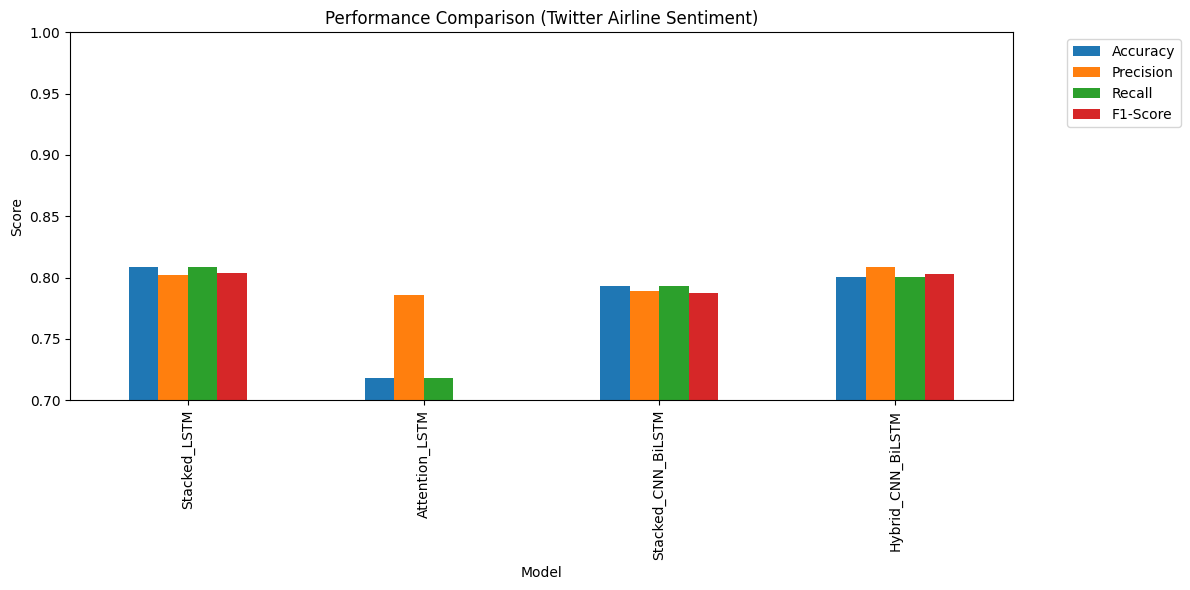

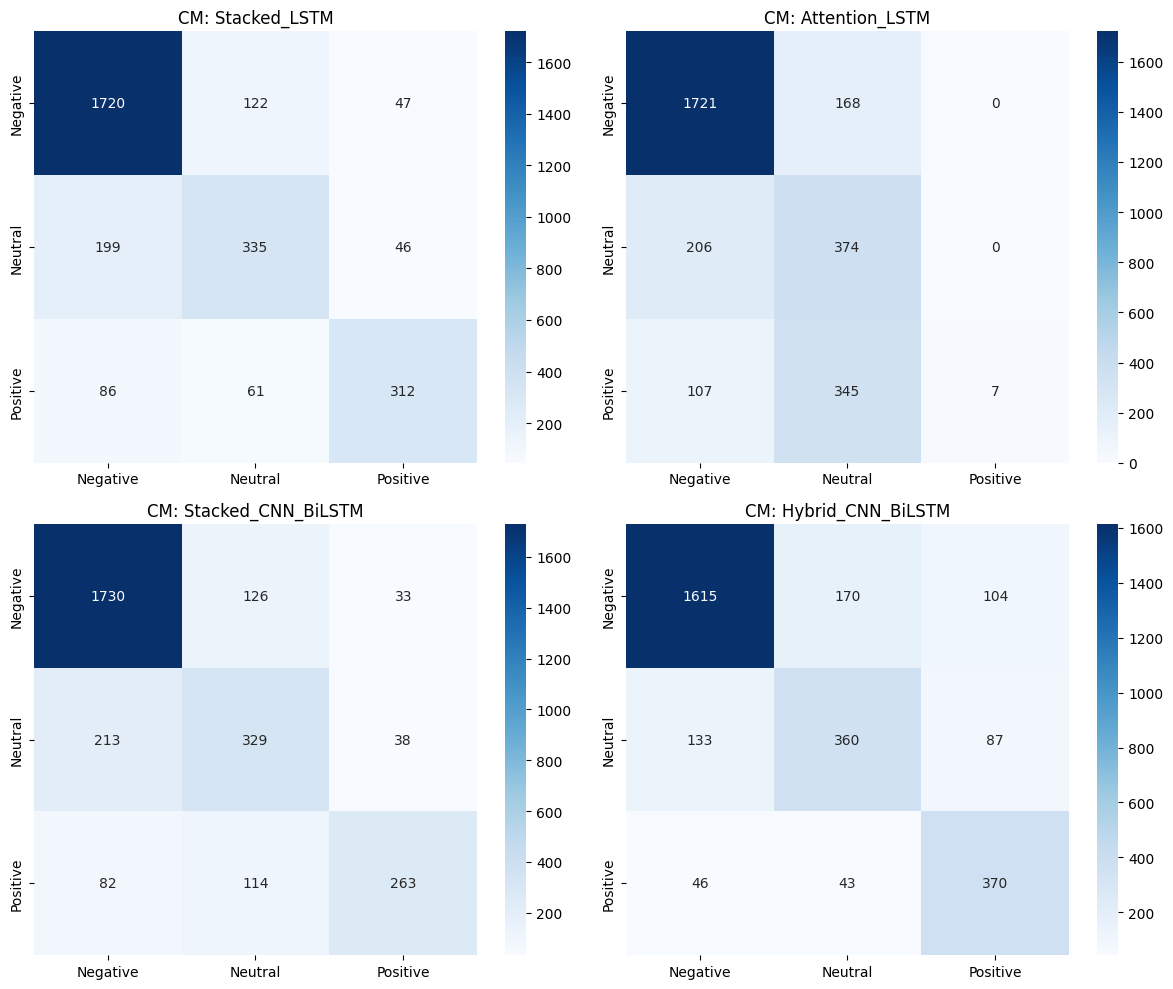

In [ ]:
import kagglehub
import pandas as pd
import numpy as np
import re
import os
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import (Input, Embedding, LSTM, Dense, Dropout,
                                     Bidirectional, Conv1D, GlobalMaxPooling1D,
                                     Concatenate, MultiHeadAttention, MaxPooling1D)
from tensorflow.keras.models import Model, Sequential

# --- 1. DATA ACQUISITION & CLEANING ---
# Download the dataset automatically using kagglehub
path = kagglehub.dataset_download("crowdflower/twitter-airline-sentiment")
csv_file = os.path.join(path, "Tweets.csv")
df = pd.read_csv(csv_file)

# Select relevant columns: 'text' for the tweet and 'airline_sentiment' for labels
df = df[['text', 'airline_sentiment']]

def clean_tweet(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text) # Remove URLs
    text = re.sub(r'@[A-Za-z0-9_]+', '', text)         # Remove Mentions
    text = re.sub(r'[^a-z\s]', '', text)               # Remove special chars/numbers
    return " ".join(text.split())

print("Cleaning data...")
df['text'] = df['text'].apply(clean_tweet)

# Map sentiment labels to integers (Negative: 0, Neutral: 1, Positive: 2)
label_map = {'negative': 0, 'neutral': 1, 'positive': 2}
df['label'] = df['airline_sentiment'].map(label_map)
df = df.dropna()

# --- 2. 70/10/20 SPLIT & TOKENIZATION ---
MAX_WORDS, MAX_LEN = 10000, 100
tokenizer = Tokenizer(num_words=MAX_WORDS)
tokenizer.fit_on_texts(df['text'])

X = pad_sequences(tokenizer.texts_to_sequences(df['text']), maxlen=MAX_LEN)
y = tf.keras.utils.to_categorical(df['label'], 3)

# Split 1: 20% for testing, 80% for train+val
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Split 2: From the 80%, take 12.5% for validation (which is 10% of the total dataset)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.125, random_state=42)

print(f"Data Split -> Train: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}")

# --- 3. MODEL ARCHITECTURES ---

def build_stacked_lstm():
    return Sequential([
        Embedding(MAX_WORDS, 128, input_length=MAX_LEN),
        LSTM(64, return_sequences=True),
        LSTM(64),
        Dropout(0.3),
        Dense(3, activation='softmax')
    ], name="Stacked_LSTM")

def build_attention_lstm():
    inputs = Input(shape=(MAX_LEN,))
    x = Embedding(MAX_WORDS, 128)(inputs)
    x = LSTM(64, return_sequences=True)(x)
    att = MultiHeadAttention(num_heads=4, key_dim=64)(x, x)
    x = GlobalMaxPooling1D()(att)
    outputs = Dense(3, activation='softmax')(x)
    return Model(inputs, outputs, name="Attention_LSTM")

def build_stacked_cnn_bilstm():
    return Sequential([
        Embedding(MAX_WORDS, 128, input_length=MAX_LEN),
        Conv1D(64, 5, activation='relu'),
        MaxPooling1D(4),
        Bidirectional(LSTM(64, return_sequences=True)),
        Bidirectional(LSTM(32)),
        Dense(3, activation='softmax')
    ], name="Stacked_CNN_BiLSTM")

def build_hybrid_cnn_bilstm():
    inputs = Input(shape=(MAX_LEN,))
    emb = Embedding(MAX_WORDS, 128)(inputs)
    cnn = Conv1D(64, 5, activation='relu')(emb)
    cnn = GlobalMaxPooling1D()(cnn)
    rnn = Bidirectional(LSTM(64))(emb)
    merged = Concatenate()([cnn, rnn])
    outputs = Dense(3, activation='softmax')(merged)
    return Model(inputs, outputs, name="Hybrid_CNN_BiLSTM")

# --- 4. TRAINING & EVALUATION ---
builders = [build_stacked_lstm, build_attention_lstm, build_stacked_cnn_bilstm, build_hybrid_cnn_bilstm]
results, cms = [], {}

for builder in builders:
    model = builder()
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    print(f"\nTraining {model.name}...")
    model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=3, batch_size=128, verbose=1)

    y_pred = np.argmax(model.predict(X_test), axis=1)
    y_true = np.argmax(y_test, axis=1)

    results.append({
        'Model': model.name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, average='weighted'),
        'Recall': recall_score(y_true, y_pred, average='weighted'),
        'F1-Score': f1_score(y_true, y_pred, average='weighted')
    })
    cms[model.name] = confusion_matrix(y_true, y_pred)

# --- 5. RESULTS & VISUALIZATION ---
perf_df = pd.DataFrame(results)
print("\n--- PERFORMANCE SUMMARY ---")
print(perf_df)

# Graph Comparison
perf_df.set_index('Model').plot(kind='bar', figsize=(12, 6))
plt.title("Performance Comparison (Twitter Airline Sentiment)")
plt.ylabel("Score")
plt.ylim(0.7, 1.0)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Confusion Matrices
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()
labels = ['Negative', 'Neutral', 'Positive']
for i, (name, matrix) in enumerate(cms.items()):
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=labels, yticklabels=labels)
    axes[i].set_title(f"CM: {name}")
plt.tight_layout()
plt.show()

In [ ]:
pip install kagglehub tensorflow pandas scikit-learn matplotlib seaborn

Using Colab cache for faster access to the 'emotion-detection-from-text' dataset.
Train: 23450 | Val: 3350 | Test: 6700

Training Stacked_LSTM...


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/3
184/184 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.2996 - loss: 1.6813 - val_accuracy: 0.3755 - val_loss: 1.5226
Epoch 2/3
184/184 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.4253 - loss: 1.4293 - val_accuracy: 0.4030 - val_loss: 1.4869
Epoch 3/3
184/184 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.5235 - loss: 1.2463 - val_accuracy: 0.3997 - val_loss: 1.5448
210/210 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step

Training Attention_LSTM...
Epoch 1/3
184/184 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.2559 - loss: 1.7114 - val_accuracy: 0.3701 - val_loss: 1.5561
Epoch 2/3
184/184 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.4044 - loss: 1.4769 - val_accuracy: 0.4063 - val_loss: 1.4919
Epoch 3/3
184/184 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.4772 - loss: 1.3172 - val_accuracy: 0.4009 - val_loss: 1.5198
210/210 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(



Training Stacked_CNN_BiLSTM...
Epoch 1/3
184/184 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.2908 - loss: 1.6897 - val_accuracy: 0.3791 - val_loss: 1.5151
Epoch 2/3
184/184 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.4297 - loss: 1.4264 - val_accuracy: 0.3949 - val_loss: 1.4932
Epoch 3/3
184/184 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.5187 - loss: 1.2417 - val_accuracy: 0.3833 - val_loss: 1.5835
210/210 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step

Training Hybrid_CNN_BiLSTM...
Epoch 1/3


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


184/184 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.3151 - loss: 1.6618 - val_accuracy: 0.4057 - val_loss: 1.4793
Epoch 2/3
184/184 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.4698 - loss: 1.3685 - val_accuracy: 0.4167 - val_loss: 1.4688
Epoch 3/3
184/184 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.5687 - loss: 1.1579 - val_accuracy: 0.3967 - val_loss: 1.5483
210/210 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step

--- Final Performance Metrics ---
                 Model  Accuracy  Precision    Recall        F1
0        Stacked_LSTM  0.415224   0.407731  0.415224  0.399852
1      Attention_LSTM  0.418358   0.412974  0.418358  0.396794
2  Stacked_CNN_BiLSTM  0.417015   0.406423  0.417015  0.382788
3   Hybrid_CNN_BiLSTM  0.421343   0.411835  0.421343  0.406290


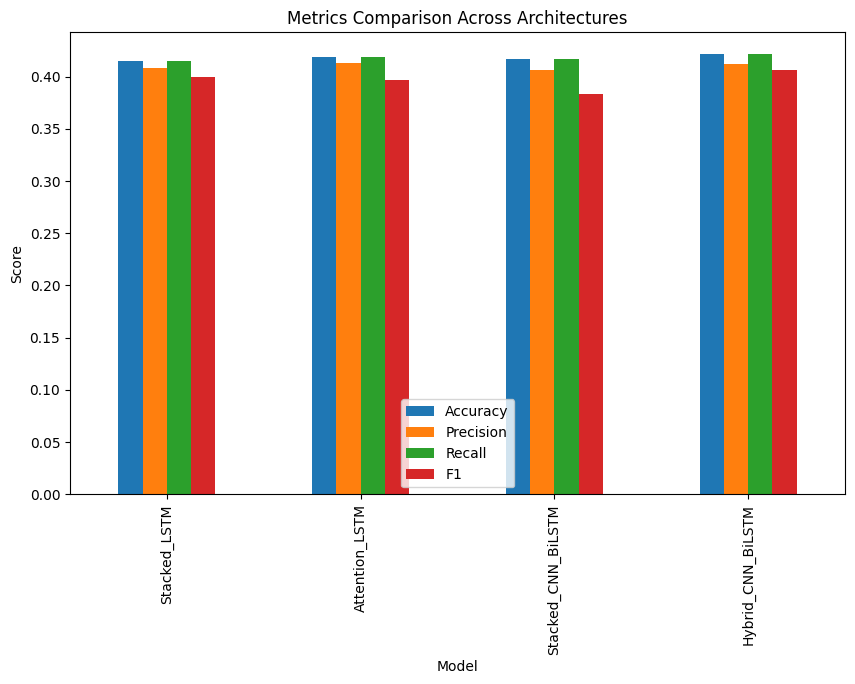

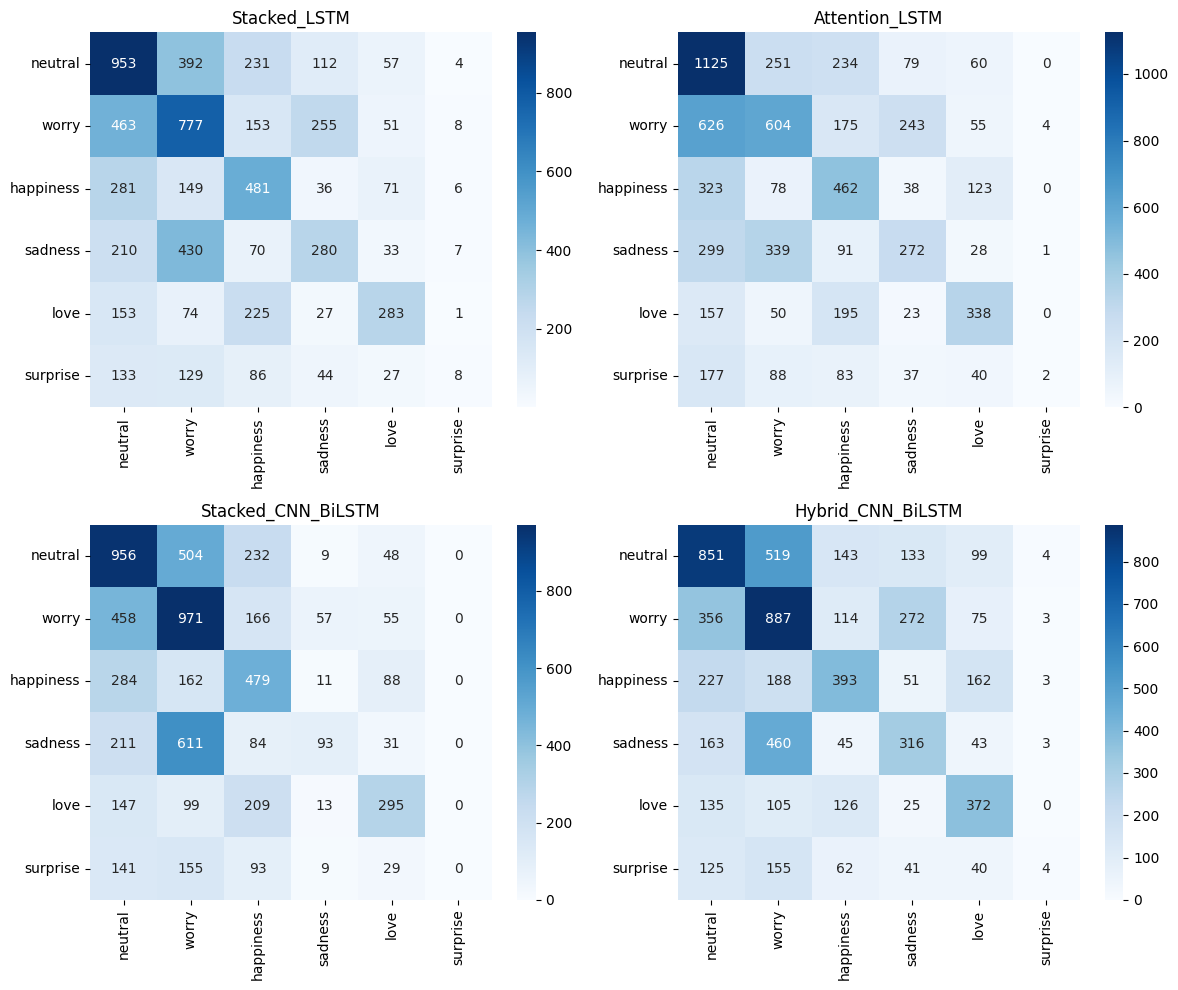

In [ ]:
import kagglehub
import pandas as pd
import numpy as np
import re
import os
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import (Input, Embedding, LSTM, Dense, Dropout,
                                     Bidirectional, Conv1D, GlobalMaxPooling1D,
                                     Concatenate, MultiHeadAttention, MaxPooling1D)
from tensorflow.keras.models import Model, Sequential

# --- 1. DATA ACQUISITION & CLEANING ---
path = kagglehub.dataset_download("pashupatigupta/emotion-detection-from-text")
csv_file = os.path.join(path, "tweet_emotions.csv")
df = pd.read_csv(csv_file)

def clean_tweet(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)
    text = re.sub(r'@[A-Za-z0-9_]+', '', text)
    text = re.sub(r'[^a-z\s]', '', text)
    return " ".join(text.split())

df['content'] = df['content'].apply(clean_tweet)

# Selecting top 6 classes for better model convergence
top_classes = df['sentiment'].value_counts().nlargest(6).index
df = df[df['sentiment'].isin(top_classes)].reset_index(drop=True)
label_map = {label: i for i, label in enumerate(top_classes)}
df['label'] = df['sentiment'].map(label_map)
num_classes = len(top_classes)

# --- 2. 70/10/20 DATA SPLIT (FIXED) ---
MAX_WORDS, MAX_LEN = 15000, 60
tokenizer = Tokenizer(num_words=MAX_WORDS)
tokenizer.fit_on_texts(df['content'])

X = pad_sequences(tokenizer.texts_to_sequences(df['content']), maxlen=MAX_LEN)
y = tf.keras.utils.to_categorical(df['label'], num_classes)

# Correct Split Logic:
# 1. Split 20% for Testing, 80% for (Train + Val)
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# 2. Split the 80% such that Val is 10% of the ORIGINAL total (0.10 / 0.80 = 0.125)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.125, random_state=42)

print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")

# --- 3. MODEL ARCHITECTURES ---

def build_stacked_lstm():
    return Sequential([
        Embedding(MAX_WORDS, 128, input_length=MAX_LEN),
        LSTM(64, return_sequences=True),
        LSTM(64),
        Dropout(0.3),
        Dense(num_classes, activation='softmax')
    ], name="Stacked_LSTM")

def build_attention_lstm():
    inputs = Input(shape=(MAX_LEN,))
    emb = Embedding(MAX_WORDS, 128)(inputs)
    lstm = LSTM(64, return_sequences=True)(emb)
    att = MultiHeadAttention(num_heads=4, key_dim=64)(lstm, lstm)
    gap = GlobalMaxPooling1D()(att)
    outputs = Dense(num_classes, activation='softmax')(gap)
    return Model(inputs, outputs, name="Attention_LSTM")

def build_stacked_cnn_bilstm():
    return Sequential([
        Embedding(MAX_WORDS, 128, input_length=MAX_LEN),
        Conv1D(64, 5, activation='relu'),
        MaxPooling1D(4),
        Bidirectional(LSTM(64, return_sequences=True)),
        Bidirectional(LSTM(32)),
        Dense(num_classes, activation='softmax')
    ], name="Stacked_CNN_BiLSTM")

def build_hybrid_cnn_bilstm():
    inputs = Input(shape=(MAX_LEN,))
    emb = Embedding(MAX_WORDS, 128)(inputs)
    cnn = Conv1D(64, 5, activation='relu')(emb)
    cnn = GlobalMaxPooling1D()(cnn)
    rnn = Bidirectional(LSTM(64))(emb)
    merged = Concatenate()([cnn, rnn])
    outputs = Dense(num_classes, activation='softmax')(merged)
    return Model(inputs, outputs, name="Hybrid_CNN_BiLSTM")

# --- 4. TRAINING & EVALUATION ---
model_list = [build_stacked_lstm, build_attention_lstm, build_stacked_cnn_bilstm, build_hybrid_cnn_bilstm]
results, cms = [], {}

for builder in model_list:
    model = builder()
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    print(f"\nTraining {model.name}...")
    model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=3, batch_size=128, verbose=1)

    y_pred = np.argmax(model.predict(X_test), axis=1)
    y_true = np.argmax(y_test, axis=1)

    results.append({
        'Model': model.name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, average='weighted'),
        'Recall': recall_score(y_true, y_pred, average='weighted'),
        'F1': f1_score(y_true, y_pred, average='weighted')
    })
    cms[model.name] = confusion_matrix(y_true, y_pred)

# --- 5. VISUALIZATION ---
res_df = pd.DataFrame(results)
print("\n--- Final Performance Metrics ---\n", res_df)

# Comparison Graph
res_df.set_index('Model').plot(kind='bar', figsize=(10, 6))
plt.title("Metrics Comparison Across Architectures")
plt.ylabel("Score")
plt.show()

# Confusion Matrices
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()
labels = list(top_classes)
for i, (name, matrix) in enumerate(cms.items()):
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=labels, yticklabels=labels)
    axes[i].set_title(name)
plt.tight_layout()
plt.show()

In [ ]:
pip install kagglehub tensorflow pandas scikit-learn matplotlib seaborn

Using Colab cache for faster access to the 'twitter-reviews-for-emotion-analysis' dataset.
Cleaning data...


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(



Training Stacked_LSTM...
Epoch 1/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 10s 43ms/step - accuracy: 0.3776 - loss: 1.5555 - val_accuracy: 0.6238 - val_loss: 1.0258
Epoch 2/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - accuracy: 0.7000 - loss: 0.8327 - val_accuracy: 0.7605 - val_loss: 0.6884
Epoch 3/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.8802 - loss: 0.3752 - val_accuracy: 0.8283 - val_loss: 0.5634
Epoch 4/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9315 - loss: 0.2151 - val_accuracy: 0.8313 - val_loss: 0.5825
Epoch 5/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9486 - loss: 0.1532 - val_accuracy: 0.8214 - val_loss: 0.6285
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step

Training Attention_LSTM...
Epoch 1/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.3800 - loss: 1.5546 - val_accuracy: 0.3772 - val_loss: 1.5015
Epoch 2/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.4995 - loss: 1.2447 - val_accuracy: 0.7774 - val_loss: 0.6310
Epoch 3/5


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


110/110 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.4011 - loss: 1.5106 - val_accuracy: 0.6257 - val_loss: 0.9917
Epoch 2/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.7642 - loss: 0.6636 - val_accuracy: 0.7914 - val_loss: 0.5808
Epoch 3/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9177 - loss: 0.2484 - val_accuracy: 0.8353 - val_loss: 0.5328
Epoch 4/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9499 - loss: 0.1529 - val_accuracy: 0.8234 - val_loss: 0.6204
Epoch 5/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9565 - loss: 0.1215 - val_accuracy: 0.8283 - val_loss: 0.6193
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step

Training Hybrid_CNN_BiLSTM...
Epoch 1/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.4533 - loss: 1.4488 - val_accuracy: 0.7166 - val_loss: 0.8990
Epoch 2/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.8158 - loss: 0.6256 - val_accuracy: 0.8673 - val_loss: 0.4152
Epoch 3/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 14

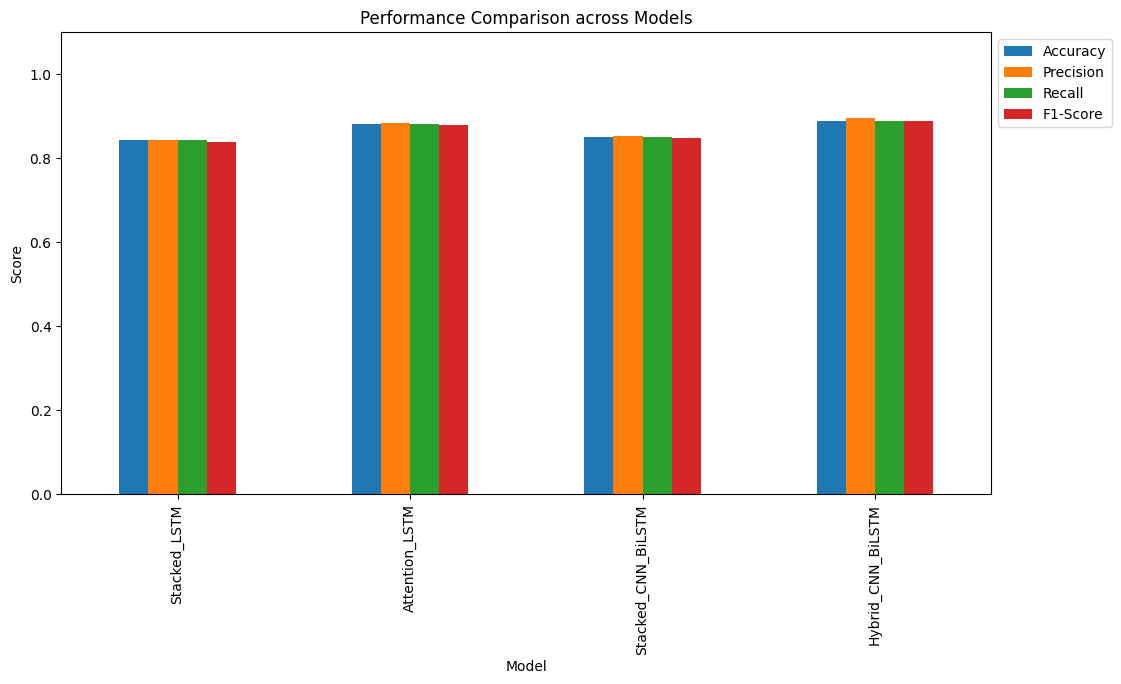

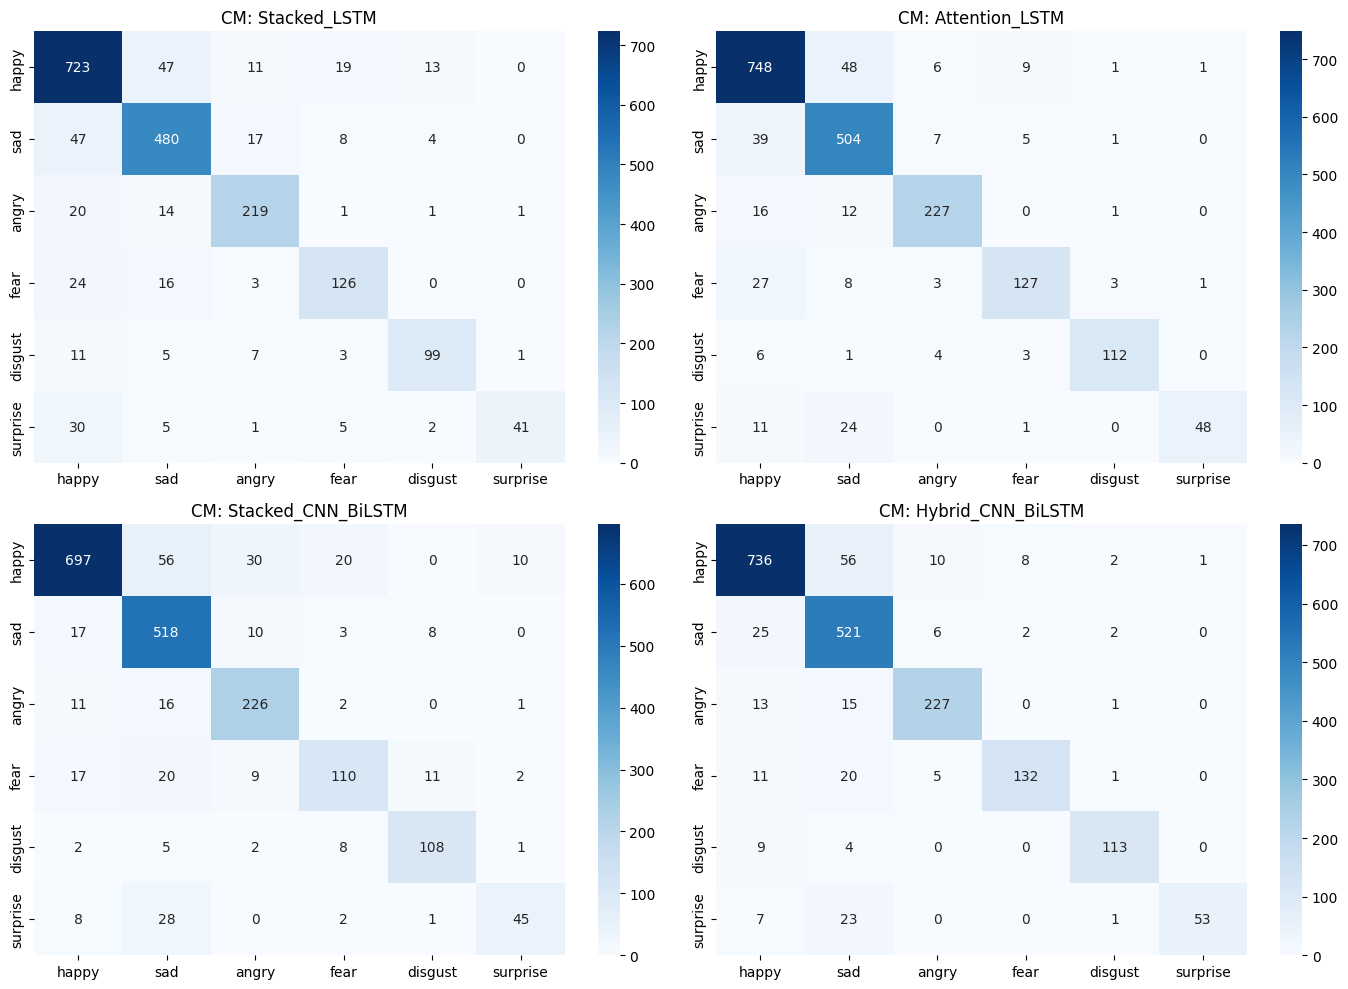

In [ ]:
import kagglehub
import pandas as pd
import numpy as np
import re
import os
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import (Input, Embedding, LSTM, Dense, Dropout,
                                     Bidirectional, Conv1D, GlobalMaxPooling1D,
                                     Concatenate, MultiHeadAttention, MaxPooling1D)
from tensorflow.keras.models import Model, Sequential

# --- 1. DATA ACQUISITION & CLEANING ---
# Programmatically download the dataset
path = kagglehub.dataset_download("shainy/twitter-reviews-for-emotion-analysis")
csv_file = os.path.join(path, "data.csv")
df = pd.read_csv(csv_file)

# Dataset columns: 'Tweets' (text) and 'Feeling' (emotion)
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text) # Remove URLs
    text = re.sub(r'@[A-Za-z0-9_]+', '', text)         # Remove Mentions
    text = re.sub(r'[^a-z\s]', '', text)               # Remove special characters
    return " ".join(text.split())

print("Cleaning data...")
df['Tweets'] = df['Tweets'].apply(clean_text)
df = df.dropna()

# Encode labels
unique_emotions = df['Feeling'].unique()
label_map = {emotion: i for i, emotion in enumerate(unique_emotions)}
df['label'] = df['Feeling'].map(label_map)
num_classes = len(unique_emotions)

# --- 2. 70/10/20 SPLIT & TOKENIZATION ---
MAX_WORDS, MAX_LEN = 10000, 100
tokenizer = Tokenizer(num_words=MAX_WORDS)
tokenizer.fit_on_texts(df['Tweets'])

X = pad_sequences(tokenizer.texts_to_sequences(df['Tweets']), maxlen=MAX_LEN)
y = tf.keras.utils.to_categorical(df['label'], num_classes)

# Fixed Split Logic:
# First split: 20% for Testing, 80% for Train+Val
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
# Second split: From the 80%, take 12.5% for Val (0.125 * 0.8 = 0.10 of total)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.125, random_state=42)

# --- 3. MODEL ARCHITECTURES ---

# A. Stacked LSTM
def build_stacked_lstm():
    return Sequential([
        Embedding(MAX_WORDS, 128, input_length=MAX_LEN),
        LSTM(64, return_sequences=True),
        LSTM(64),
        Dropout(0.3),
        Dense(num_classes, activation='softmax')
    ], name="Stacked_LSTM")

# B. Attention Based LSTM
def build_attention_lstm():
    inputs = Input(shape=(MAX_LEN,))
    x = Embedding(MAX_WORDS, 128)(inputs)
    x = LSTM(64, return_sequences=True)(x)
    att = MultiHeadAttention(num_heads=4, key_dim=64)(x, x)
    x = GlobalMaxPooling1D()(att)
    outputs = Dense(num_classes, activation='softmax')(x)
    return Model(inputs, outputs, name="Attention_LSTM")

# C. Stacked CNN-Bi-LSTM
def build_stacked_cnn_bilstm():
    return Sequential([
        Embedding(MAX_WORDS, 128, input_length=MAX_LEN),
        Conv1D(64, 5, activation='relu'),
        MaxPooling1D(4),
        Bidirectional(LSTM(64, return_sequences=True)),
        Bidirectional(LSTM(32)),
        Dense(num_classes, activation='softmax')
    ], name="Stacked_CNN_BiLSTM")

# D. Hybrid CNN-BiLSTM (Parallel)
def build_hybrid_cnn_bilstm():
    inputs = Input(shape=(MAX_LEN,))
    emb = Embedding(MAX_WORDS, 128)(inputs)
    # CNN Branch
    cnn = Conv1D(64, 5, activation='relu')(emb)
    cnn = GlobalMaxPooling1D()(cnn)
    # BiLSTM Branch
    rnn = Bidirectional(LSTM(64))(emb)
    # Merge
    merged = Concatenate()([cnn, rnn])
    outputs = Dense(num_classes, activation='softmax')(merged)
    return Model(inputs, outputs, name="Hybrid_CNN_BiLSTM")

# --- 4. TRAINING & EVALUATION ---
builders = [build_stacked_lstm, build_attention_lstm, build_stacked_cnn_bilstm, build_hybrid_cnn_bilstm]
results, cms = [], {}

for builder in builders:
    model = builder()
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    print(f"\nTraining {model.name}...")
    model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=5, batch_size=64, verbose=1)

    # Predict on test set
    y_pred = np.argmax(model.predict(X_test), axis=1)
    y_true = np.argmax(y_test, axis=1)

    results.append({
        'Model': model.name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, average='weighted'),
        'Recall': recall_score(y_true, y_pred, average='weighted'),
        'F1-Score': f1_score(y_true, y_pred, average='weighted')
    })
    cms[model.name] = confusion_matrix(y_true, y_pred)

# --- 5. VISUALIZATION ---
perf_df = pd.DataFrame(results)
print("\n--- PERFORMANCE SUMMARY ---")
print(perf_df)

# Graph Comparison
perf_df.set_index('Model').plot(kind='bar', figsize=(12, 6))
plt.title("Performance Comparison across Models")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.legend(bbox_to_anchor=(1, 1))
plt.show()

# Confusion Matrices
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
for i, (name, matrix) in enumerate(cms.items()):
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=unique_emotions, yticklabels=unique_emotions)
    axes[i].set_title(f"CM: {name}")
plt.tight_layout()
plt.show()

In [ ]:
pip install kagglehub tensorflow pandas scikit-learn matplotlib seaborn

Using Colab cache for faster access to the 'emotions-dataset-for-nlp' dataset.
Cleaning data...


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(



Training Stacked_LSTM...
Epoch 1/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 10s 42ms/step - accuracy: 0.3386 - loss: 1.6079 - val_accuracy: 0.5225 - val_loss: 1.3879
Epoch 2/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.6041 - loss: 1.0790 - val_accuracy: 0.7920 - val_loss: 0.6227
Epoch 3/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.8690 - loss: 0.4041 - val_accuracy: 0.8545 - val_loss: 0.4140
Epoch 4/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9340 - loss: 0.2036 - val_accuracy: 0.8815 - val_loss: 0.3798
Epoch 5/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9659 - loss: 0.1104 - val_accuracy: 0.8880 - val_loss: 0.3505
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step

Training Attention_LSTM...
Epoch 1/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.3171 - loss: 1.6131 - val_accuracy: 0.3300 - val_loss: 1.5828
Epoch 2/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.3452 - loss: 1.5409 - val_accuracy: 0.5315 - val_loss: 1.0622
Epoch 3/

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


110/110 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.3300 - loss: 1.6066 - val_accuracy: 0.5215 - val_loss: 1.3515
Epoch 2/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.6221 - loss: 0.9768 - val_accuracy: 0.7930 - val_loss: 0.4985
Epoch 3/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.8785 - loss: 0.3175 - val_accuracy: 0.8970 - val_loss: 0.2928
Epoch 4/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9477 - loss: 0.1561 - val_accuracy: 0.8985 - val_loss: 0.3013
Epoch 5/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9701 - loss: 0.0940 - val_accuracy: 0.8895 - val_loss: 0.3546
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step

Training Hybrid_CNN_BiLSTM...
Epoch 1/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.3574 - loss: 1.5794 - val_accuracy: 0.6165 - val_loss: 1.0141
Epoch 2/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.7998 - loss: 0.6365 - val_accuracy: 0.9145 - val_loss: 0.2572
Epoch 3/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 

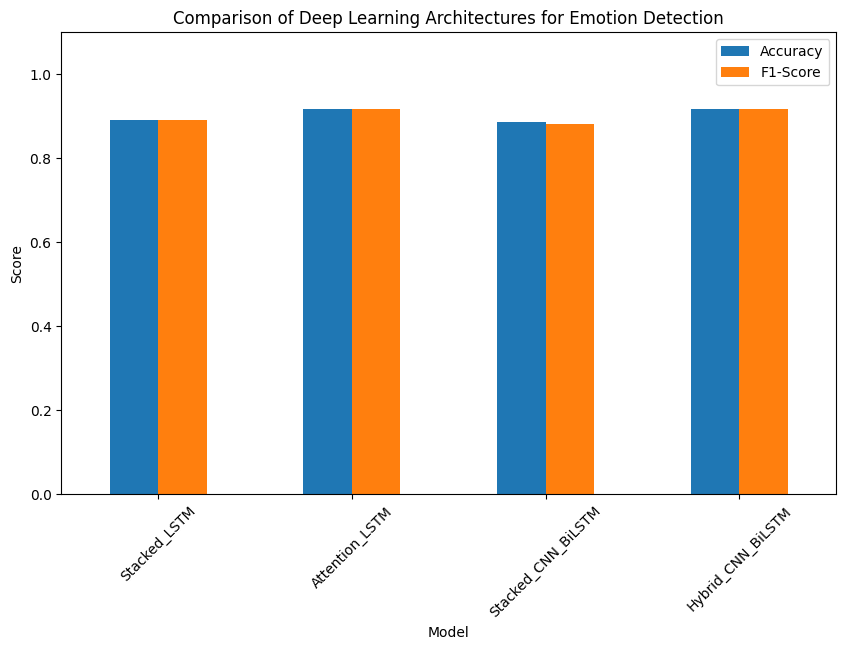

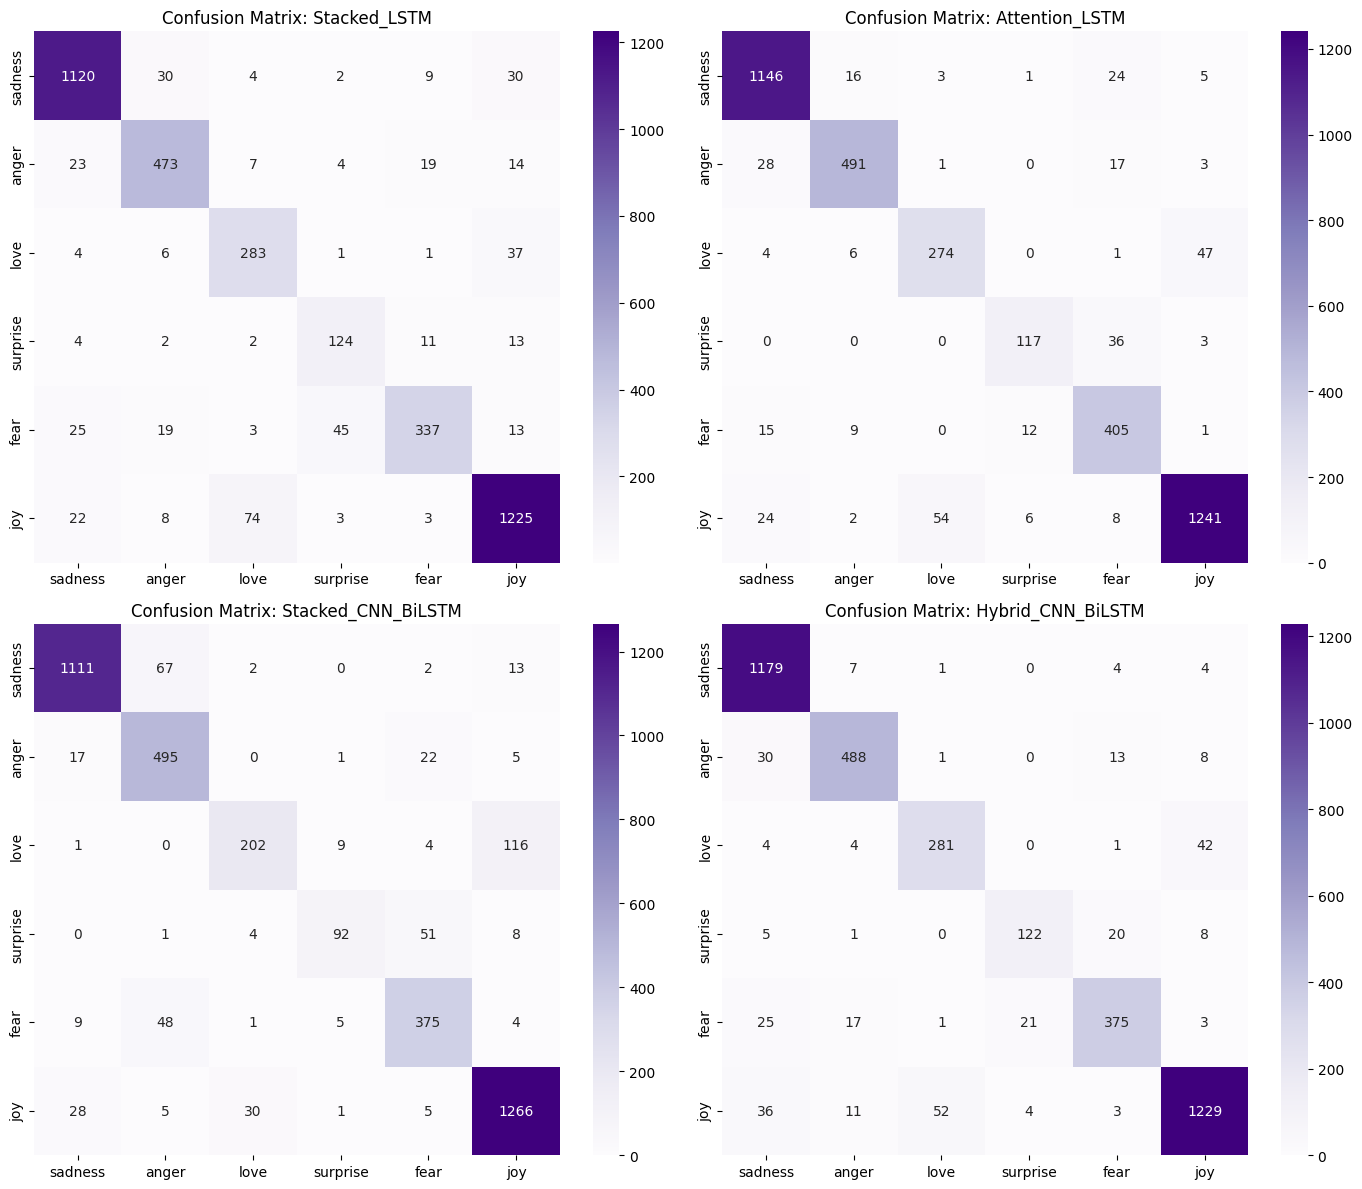

In [ ]:
import kagglehub
import pandas as pd
import numpy as np
import re
import os
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import (Input, Embedding, LSTM, Dense, Dropout,
                                     Bidirectional, Conv1D, GlobalMaxPooling1D,
                                     Concatenate, MultiHeadAttention, MaxPooling1D)
from tensorflow.keras.models import Model, Sequential

# --- 1. DATA ACQUISITION & CLEANING ---
# Downloading the dataset (commonly known as the 'dair-ai/emotion' dataset on Kaggle)
path = kagglehub.dataset_download("praveengovi/emotions-dataset-for-nlp")

# This dataset typically contains 'train.txt', 'val.txt', and 'test.txt'
# We merge them to create a single dataframe for a custom 70/10/20 split
def load_and_merge(path):
    files = ['train.txt', 'val.txt', 'test.txt']
    dfs = []
    for f in files:
        file_path = os.path.join(path, f)
        # The file is semicolon separated: "text;label"
        temp_df = pd.read_csv(file_path, sep=';', header=None, names=['text', 'emotion'])
        dfs.append(temp_df)
    return pd.concat(dfs, ignore_index=True)

df = load_and_merge(path)

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', '', text) # Remove punctuation and numbers
    return " ".join(text.split())

print("Cleaning data...")
df['text'] = df['text'].apply(clean_text)

# Map labels
unique_emotions = df['emotion'].unique()
label_map = {emotion: i for i, emotion in enumerate(unique_emotions)}
df['label'] = df['emotion'].map(label_map)
num_classes = len(unique_emotions)

# --- 2. 70/10/20 SPLIT & TOKENIZATION ---
MAX_WORDS, MAX_LEN = 10000, 80
tokenizer = Tokenizer(num_words=MAX_WORDS)
tokenizer.fit_on_texts(df['text'])

X = pad_sequences(tokenizer.texts_to_sequences(df['text']), maxlen=MAX_LEN)
y = tf.keras.utils.to_categorical(df['label'], num_classes)

# Split 1: 20% for Testing, 80% for Train+Val
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Split 2: From 80%, take 12.5% for Val (0.125 * 0.8 = 0.10 of total)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.125, random_state=42)

# --- 3. MODEL ARCHITECTURES ---

# A. Stacked LSTM
def build_stacked_lstm():
    return Sequential([
        Embedding(MAX_WORDS, 128, input_length=MAX_LEN),
        LSTM(64, return_sequences=True),
        LSTM(64),
        Dropout(0.3),
        Dense(num_classes, activation='softmax')
    ], name="Stacked_LSTM")

# B. Attention Based LSTM
def build_attention_lstm():
    inputs = Input(shape=(MAX_LEN,))
    x = Embedding(MAX_WORDS, 128)(inputs)
    x = LSTM(64, return_sequences=True)(x)
    # Self-Attention layer
    att = MultiHeadAttention(num_heads=4, key_dim=64)(x, x)
    x = GlobalMaxPooling1D()(att)
    outputs = Dense(num_classes, activation='softmax')(x)
    return Model(inputs, outputs, name="Attention_LSTM")

# C. Stacked CNN-Bi-LSTM
def build_stacked_cnn_bilstm():
    return Sequential([
        Embedding(MAX_WORDS, 128, input_length=MAX_LEN),
        Conv1D(64, 5, activation='relu'),
        MaxPooling1D(4),
        Bidirectional(LSTM(64, return_sequences=True)),
        Bidirectional(LSTM(32)),
        Dense(num_classes, activation='softmax')
    ], name="Stacked_CNN_BiLSTM")

# D. Hybrid CNN-BiLSTM
def build_hybrid_cnn_bilstm():
    inputs = Input(shape=(MAX_LEN,))
    emb = Embedding(MAX_WORDS, 128)(inputs)
    # CNN Path
    cnn = Conv1D(64, 5, activation='relu')(emb)
    cnn = GlobalMaxPooling1D()(cnn)
    # BiLSTM Path
    rnn = Bidirectional(LSTM(64))(emb)
    # Fusion
    merged = Concatenate()([cnn, rnn])
    outputs = Dense(num_classes, activation='softmax')(merged)
    return Model(inputs, outputs, name="Hybrid_CNN_BiLSTM")

# --- 4. TRAINING & EVALUATION ---
model_funcs = [build_stacked_lstm, build_attention_lstm, build_stacked_cnn_bilstm, build_hybrid_cnn_bilstm]
results, cms = [], {}

for func in model_funcs:
    model = func()
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    print(f"\nTraining {model.name}...")
    # Training for 5 epochs for demonstration
    model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=5, batch_size=128, verbose=1)

    # Prediction
    y_pred = np.argmax(model.predict(X_test), axis=1)
    y_true = np.argmax(y_test, axis=1)

    results.append({
        'Model': model.name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, average='weighted'),
        'Recall': recall_score(y_true, y_pred, average='weighted'),
        'F1-Score': f1_score(y_true, y_pred, average='weighted')
    })
    cms[model.name] = confusion_matrix(y_true, y_pred)

# --- 5. VISUALIZATION & COMPARISON ---
perf_df = pd.DataFrame(results)
print("\n--- PERFORMANCE SUMMARY ---")
print(perf_df)

# Graph comparing Accuracy and F1-Score
perf_df.set_index('Model')[['Accuracy', 'F1-Score']].plot(kind='bar', figsize=(10, 6))
plt.title("Comparison of Deep Learning Architectures for Emotion Detection")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=45)
plt.show()

# Confusion Matrices
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()
for i, (name, matrix) in enumerate(cms.items()):
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Purples', ax=axes[i],
                xticklabels=unique_emotions, yticklabels=unique_emotions)
    axes[i].set_title(f"Confusion Matrix: {name}")
plt.tight_layout()
plt.show()

In [ ]:
pip install kagglehub tensorflow pandas scikit-learn matplotlib seaborn

Using Colab cache for faster access to the 'emotions-dataset-for-nlp' dataset.
Cleaning data...


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(



Training Stacked_LSTM...
Epoch 1/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 10s 44ms/step - accuracy: 0.3302 - loss: 1.6231 - val_accuracy: 0.5395 - val_loss: 1.2420
Epoch 2/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - accuracy: 0.6522 - loss: 0.9291 - val_accuracy: 0.7795 - val_loss: 0.5804
Epoch 3/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8516 - loss: 0.3902 - val_accuracy: 0.9015 - val_loss: 0.3114
Epoch 4/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9463 - loss: 0.1684 - val_accuracy: 0.9060 - val_loss: 0.3228
Epoch 5/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9721 - loss: 0.0950 - val_accuracy: 0.9040 - val_loss: 0.3019
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step

Training Attention_LSTM...
Epoch 1/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.3081 - loss: 1.6115 - val_accuracy: 0.3300 - val_loss: 1.5817
Epoch 2/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.3433 - loss: 1.5304 - val_accuracy: 0.4920 - val_loss: 1.0935
Epoch 3/

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


110/110 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.3624 - loss: 1.5889 - val_accuracy: 0.5655 - val_loss: 1.1812
Epoch 2/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.6488 - loss: 0.9165 - val_accuracy: 0.8035 - val_loss: 0.5599
Epoch 3/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.8635 - loss: 0.3930 - val_accuracy: 0.8645 - val_loss: 0.3769
Epoch 4/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9335 - loss: 0.1922 - val_accuracy: 0.8970 - val_loss: 0.2880
Epoch 5/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9672 - loss: 0.1043 - val_accuracy: 0.9055 - val_loss: 0.2994
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step

Training Hybrid_CNN_BiLSTM...
Epoch 1/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.3577 - loss: 1.5822 - val_accuracy: 0.6900 - val_loss: 0.9481
Epoch 2/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.8227 - loss: 0.5821 - val_accuracy: 0.9260 - val_loss: 0.1992
Epoch 3/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 

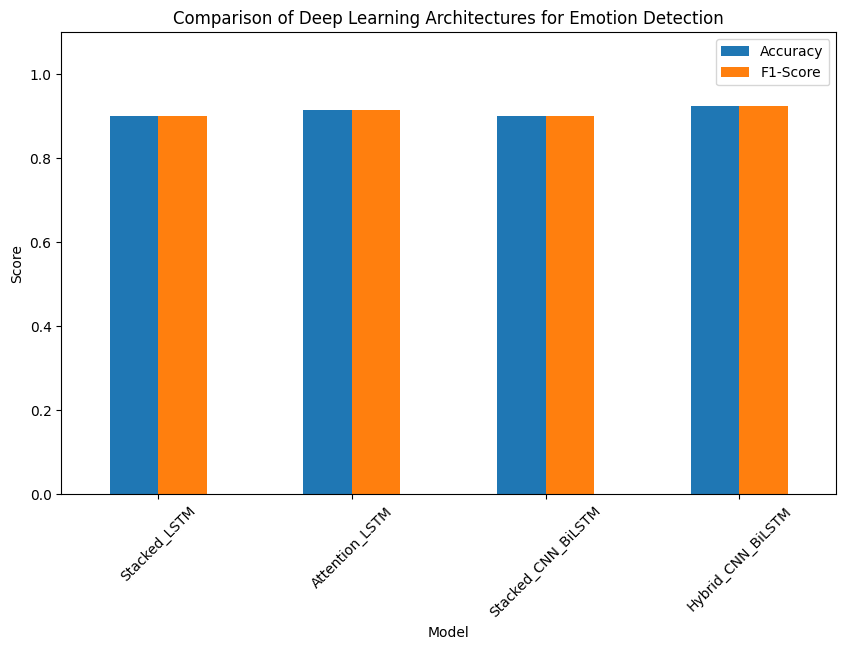

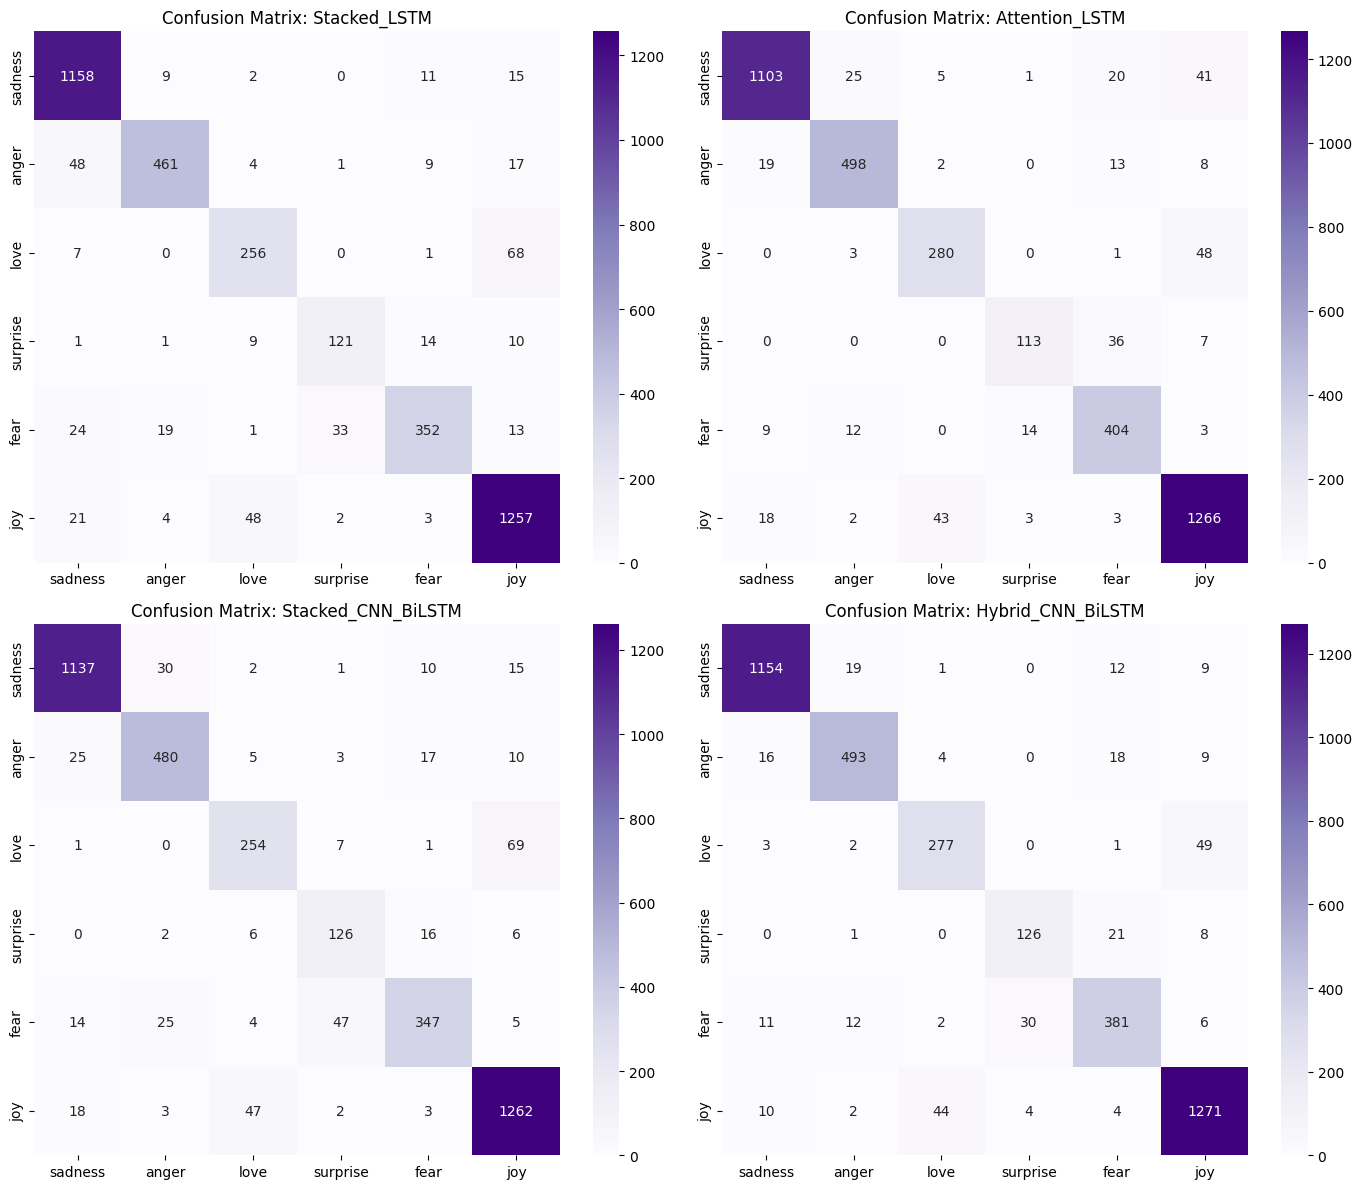

In [ ]:
import kagglehub
import pandas as pd
import numpy as np
import re
import os
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import (Input, Embedding, LSTM, Dense, Dropout,
                                     Bidirectional, Conv1D, GlobalMaxPooling1D,
                                     Concatenate, MultiHeadAttention, MaxPooling1D)
from tensorflow.keras.models import Model, Sequential

# --- 1. DATA ACQUISITION & CLEANING ---
# Downloading the dataset (commonly known as the 'dair-ai/emotion' dataset on Kaggle)
path = kagglehub.dataset_download("praveengovi/emotions-dataset-for-nlp")

# This dataset typically contains 'train.txt', 'val.txt', and 'test.txt'
# We merge them to create a single dataframe for a custom 70/10/20 split
def load_and_merge(path):
    files = ['train.txt', 'val.txt', 'test.txt']
    dfs = []
    for f in files:
        file_path = os.path.join(path, f)
        # The file is semicolon separated: "text;label"
        temp_df = pd.read_csv(file_path, sep=';', header=None, names=['text', 'emotion'])
        dfs.append(temp_df)
    return pd.concat(dfs, ignore_index=True)

df = load_and_merge(path)

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', '', text) # Remove punctuation and numbers
    return " ".join(text.split())

print("Cleaning data...")
df['text'] = df['text'].apply(clean_text)

# Map labels
unique_emotions = df['emotion'].unique()
label_map = {emotion: i for i, emotion in enumerate(unique_emotions)}
df['label'] = df['emotion'].map(label_map)
num_classes = len(unique_emotions)

# --- 2. 70/10/20 SPLIT & TOKENIZATION ---
MAX_WORDS, MAX_LEN = 10000, 80
tokenizer = Tokenizer(num_words=MAX_WORDS)
tokenizer.fit_on_texts(df['text'])

X = pad_sequences(tokenizer.texts_to_sequences(df['text']), maxlen=MAX_LEN)
y = tf.keras.utils.to_categorical(df['label'], num_classes)

# Split 1: 20% for Testing, 80% for Train+Val
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Split 2: From 80%, take 12.5% for Val (0.125 * 0.8 = 0.10 of total)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.125, random_state=42)

# --- 3. MODEL ARCHITECTURES ---

# A. Stacked LSTM
def build_stacked_lstm():
    return Sequential([
        Embedding(MAX_WORDS, 128, input_length=MAX_LEN),
        LSTM(64, return_sequences=True),
        LSTM(64),
        Dropout(0.3),
        Dense(num_classes, activation='softmax')
    ], name="Stacked_LSTM")

# B. Attention Based LSTM
def build_attention_lstm():
    inputs = Input(shape=(MAX_LEN,))
    x = Embedding(MAX_WORDS, 128)(inputs)
    x = LSTM(64, return_sequences=True)(x)
    # Self-Attention layer
    att = MultiHeadAttention(num_heads=4, key_dim=64)(x, x)
    x = GlobalMaxPooling1D()(att)
    outputs = Dense(num_classes, activation='softmax')(x)
    return Model(inputs, outputs, name="Attention_LSTM")

# C. Stacked CNN-Bi-LSTM
def build_stacked_cnn_bilstm():
    return Sequential([
        Embedding(MAX_WORDS, 128, input_length=MAX_LEN),
        Conv1D(64, 5, activation='relu'),
        MaxPooling1D(4),
        Bidirectional(LSTM(64, return_sequences=True)),
        Bidirectional(LSTM(32)),
        Dense(num_classes, activation='softmax')
    ], name="Stacked_CNN_BiLSTM")

# D. Hybrid CNN-BiLSTM
def build_hybrid_cnn_bilstm():
    inputs = Input(shape=(MAX_LEN,))
    emb = Embedding(MAX_WORDS, 128)(inputs)
    # CNN Path
    cnn = Conv1D(64, 5, activation='relu')(emb)
    cnn = GlobalMaxPooling1D()(cnn)
    # BiLSTM Path
    rnn = Bidirectional(LSTM(64))(emb)
    # Fusion
    merged = Concatenate()([cnn, rnn])
    outputs = Dense(num_classes, activation='softmax')(merged)
    return Model(inputs, outputs, name="Hybrid_CNN_BiLSTM")

# --- 4. TRAINING & EVALUATION ---
model_funcs = [build_stacked_lstm, build_attention_lstm, build_stacked_cnn_bilstm, build_hybrid_cnn_bilstm]
results, cms = [], {}

for func in model_funcs:
    model = func()
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    print(f"\nTraining {model.name}...")
    # Training for 5 epochs for demonstration
    model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=5, batch_size=128, verbose=1)

    # Prediction
    y_pred = np.argmax(model.predict(X_test), axis=1)
    y_true = np.argmax(y_test, axis=1)

    results.append({
        'Model': model.name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, average='weighted'),
        'Recall': recall_score(y_true, y_pred, average='weighted'),
        'F1-Score': f1_score(y_true, y_pred, average='weighted')
    })
    cms[model.name] = confusion_matrix(y_true, y_pred)

# --- 5. VISUALIZATION & COMPARISON ---
perf_df = pd.DataFrame(results)
print("\n--- PERFORMANCE SUMMARY ---")
print(perf_df)

# Graph comparing Accuracy and F1-Score
perf_df.set_index('Model')[['Accuracy', 'F1-Score']].plot(kind='bar', figsize=(10, 6))
plt.title("Comparison of Deep Learning Architectures for Emotion Detection")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=45)
plt.show()

# Confusion Matrices
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()
for i, (name, matrix) in enumerate(cms.items()):
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Purples', ax=axes[i],
                xticklabels=unique_emotions, yticklabels=unique_emotions)
    axes[i].set_title(f"Confusion Matrix: {name}")
plt.tight_layout()
plt.show()